# 04 Test: the chosen model on the test period, once

Until now, we have only used the backtest, from 2013 to September 2024. In the present notebook, we finally look at the **test period**, October 2024 to September 2026: 24 months that none of our choices has seen. This is the only notebook that uses them. The question is simple: does the model we chose on the backtest also do well on months it has never seen? Only that tells us how it would do for SEM in practice.

To do this, we read the cleaned series from `01_preprocess.ipynb` (`../data/processed/asylum_clean.csv`) and the backtest errors from `03_evaluate.ipynb` (`../output/tables/03_backtest_errors.csv`), so that we can compare the two periods. We save the test forecasts (`../data/processed/test_forecasts.csv`), the test errors (`../output/tables/04_test_errors.csv`) and a figure of the forecasts two months ahead (`../output/figures/04_test_forecasts_h2.png`).

The choice was made **before** this notebook was run. In `03_evaluate.ipynb`, section 8, we chose the **linear regression** of `02b`: it is as good as Ridge at $h = 2$ and simpler. That choice was committed to GitHub before this notebook, so anyone can check the order of the two commits. We do not change it after seeing the results below; they are reported as they are, good or bad. Otherwise the test would no longer be an honest check.

After the first run of this notebook, we added one more simple rule: the **random walk**, which repeats the last known month (`02_estimate.ipynb`). We report it here for information only. It is not a candidate model, and the chosen model, its forecasts and its test result are exactly the same as in the first run.

One limit of this test is worth saying at the start. We test only the chosen model and the 12-month average, plus the random walk for information. The best SARIMA model, one of the baselines of our plan and practically as good as our model in the backtest (`03_evaluate.ipynb`, section 3), is not part of the test. So the test can tell us whether our model beats the simple rule on new months, but not whether it beats SARIMA.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

np.random.seed(42)
plt.style.use("seaborn-v0_8-muted")

## 1. Load the whole series

For the first time, we load all 225 months, including the 24 months of the test period. We need the whole series because each test forecast is made with all the months known at its date, which includes the backtest and, as time goes on, the earlier test months.

In [2]:
clean = pd.read_csv("../data/processed/asylum_clean.csv")
clean["month"] = pd.to_datetime(clean["month"])
clean = clean.set_index("month")

y = clean["applicants_total"].to_numpy(dtype=float)
log_y = clean["log_applicants"].to_numpy(dtype=float)
months = clean.index

last_backtest = int(np.where(months == pd.Timestamp("2024-09-01"))[0][0])
last_month = len(months) - 1
H_MAX = 3

print(clean["period"].value_counts())
print("Last backtest month:", months[last_backtest], "| last month:", months[last_month])

period
backtest    141
training     60
test         24
Name: count, dtype: int64
Last backtest month: 2024-09-01 00:00:00 | last month: 2026-09-01 00:00:00


## 2. The models, exactly as in the backtest

The test only means something if the models are exactly the ones we evaluated in the backtest. If we changed anything now, we would be testing a different model from the one we chose. So we copy the code without any change.

The **linear regression** comes from `02b_estimate_regression.ipynb`: one model per horizon, predicting the change of log applications from the last two monthly changes, the same change one year earlier and the calendar month. The function `make_table`, which builds these features, is copied as it is. We compare it with the **12-month average** from `02_estimate.ipynb`, the average of the last 12 known months: it was the best simple rule in the backtest, so our main comparison (`03_evaluate.ipynb`, section 3) is between these two. For information, we also include the **random walk**, added after the test run: the last known month, used as the forecast for every horizon.

In [3]:
def make_table(h):
    # Copied from 02b: one row per origin t, features known at t, target = change of log from t to t + h
    rows = []
    for t in range(12, len(log_y) - h):
        rows.append({
            "t": t,
            "change_last_month": log_y[t] - log_y[t - 1],
            "change_month_before": log_y[t - 1] - log_y[t - 2],
            "same_change_last_year": log_y[t + h - 12] - log_y[t - 12],
            "calendar_month": months[t + h].month,
            "target": log_y[t + h] - log_y[t],
        })
    table = pd.DataFrame(rows).set_index("t")
    dummies = pd.get_dummies(table["calendar_month"], prefix="month", drop_first=True).astype(float)
    X = pd.concat([table[["change_last_month", "change_month_before", "same_change_last_year"]], dummies], axis=1)
    return X, table["target"]


def random_walk(train_y, h_max):
    # Copied from 02: the last known month, the same for every horizon
    return np.log(np.full(h_max, train_y[-1]))


def average_12(train_y, h_max):
    # Copied from 02: average of the last 12 known months, the same for every horizon
    average = train_y[-12:].mean()
    return np.log(np.full(h_max, average))


tables = {h: make_table(h) for h in range(1, H_MAX + 1)}

## 3. Forecasts for the test period

We now continue the backtest into the test period, with exactly the same rule. At each origin, the models are fitted on all months known at that origin and nothing after it, and we forecast $h = 1$, 2 and 3. The origins go from September 2024, the last backtest month, to August 2026. So the forecast for, say, March 2026 is made with the months up to December 2025 ($h = 3$), January 2026 ($h = 2$) or February 2026 ($h = 1$), just as a planner would have had them.

This is the time-series version of "train on all training data, then test". There is no single model fitted once and then applied to all test months, because in practice SEM would refit the model every month when a new number arrives. What we fixed before the test is the specification: the features, the model and the absence of a penalty. The fitted coefficients are updated month by month.

We expect 24 forecasts for $h = 1$, 23 for $h = 2$ and 22 for $h = 3$ per model. The origins start in September 2024, the last backtest month, so the first forecast month is October 2024 at $h = 1$, November 2024 at $h = 2$ and December 2024 at $h = 3$. Forecasts from earlier origins into the test period were already dropped in the backtest, so these first months are not scored at the longer horizons. At the other end, the last origins cannot look beyond September 2026.

In [4]:
rows = []

for t in range(last_backtest, last_month):          # origins 2024-09 to 2026-08
    for h in range(1, H_MAX + 1):
        target_pos = t + h
        if target_pos > last_month:
            continue

        # Linear regression: training rows whose target is known at the origin
        X, target = tables[h]
        train_rows = list(range(X.index.min(), t - h + 1))
        assert max(train_rows) + h <= t                     # no training target after the origin
        model = make_pipeline(StandardScaler(), LinearRegression()).fit(X.loc[train_rows], target.loc[train_rows])
        forecast_lr = log_y[t] + model.predict(X.loc[[t]])[0]

        # 12-month average: the last 12 months up to the origin
        forecast_avg = average_12(y[: t + 1], H_MAX)[h - 1]

        # Random walk: the last month up to the origin (added after the test run, for information)
        forecast_rw = random_walk(y[: t + 1], H_MAX)[h - 1]

        for name, forecast_log in [("Linear regression", forecast_lr), ("12-month average", forecast_avg),
                                   ("Random walk", forecast_rw)]:
            rows.append({
                "model": name, "origin": months[t], "month": months[target_pos], "h": h,
                "forecast_log": forecast_log, "actual_log": log_y[target_pos],
                "forecast": np.exp(forecast_log), "actual": y[target_pos],
            })

test_forecasts = pd.DataFrame(rows)
print(test_forecasts.groupby(["model", "h"]).size())
print()
print("All forecast months in the test period:", (test_forecasts["month"] >= pd.Timestamp("2024-10-01")).all())
print("All forecast months after their origin:", (test_forecasts["month"] > test_forecasts["origin"]).all())
print("Missing or infinite forecasts:", (~np.isfinite(test_forecasts["forecast_log"])).sum())

model              h
12-month average   1    24
                   2    23
                   3    22
Linear regression  1    24
                   2    23
                   3    22
Random walk        1    24
                   2    23
                   3    22
dtype: int64

All forecast months in the test period: True
All forecast months after their origin: True
Missing or infinite forecasts: 0


The checks show that each model has 24 forecasts for $h = 1$, 23 for $h = 2$ and 22 for $h = 3$, as expected. All forecast months lie in the test period and after their origin, and no forecast is missing. These checks confirm the counts and the dates, but on their own they cannot prove that no forecast used later months. What guarantees this is the way the training rows are built: only origins whose target month is already known at the forecast origin (`train_rows` in the loop). The `assert` repeats this rule, as a guard in case the code is changed later. So the test errors below are what a planner could have achieved, with today's values of the data.

## 4. Test errors

We measure the errors in exactly the same way as in `03_evaluate.ipynb`, so that the test and the backtest can be compared. The first is the MAE in applications per month, our main measure because a planner can use it directly. The second is the RMSE in logs, which looks at relative errors and punishes large misses more.

In [5]:
test_forecasts["abs_error"] = (test_forecasts["actual"] - test_forecasts["forecast"]).abs()
test_forecasts["sq_error_log"] = (test_forecasts["actual_log"] - test_forecasts["forecast_log"]) ** 2

grouped = test_forecasts.groupby(["model", "h"])
test_errors = pd.DataFrame({
    "MAE (persons)": grouped["abs_error"].mean(),
    "RMSE (log)": np.sqrt(grouped["sq_error_log"].mean()),
    "forecasts": grouped["abs_error"].size(),
}).reset_index()

test_errors.to_csv("../output/tables/04_test_errors.csv", index=False)
test_errors.round(3)

,model,h,MAE (persons),RMSE (log),forecasts
0,12-month average,1,297.309,0.177,24
1,12-month average,2,331.286,0.191,23
2,12-month average,3,359.299,0.204,22
3,Linear regression,1,149.287,0.098,24
4,Linear regression,2,187.966,0.112,23
5,Linear regression,3,217.125,0.144,22
6,Random walk,1,187.083,0.104,24
7,Random walk,2,269.130,0.161,23
8,Random walk,3,358.409,0.213,22


### The main comparison at $h = 2$

In [6]:
h2 = test_errors[test_errors["h"] == 2].set_index("model")
mae_lr, mae_avg = h2.loc["Linear regression", "MAE (persons)"], h2.loc["12-month average", "MAE (persons)"]
rmse_lr, rmse_avg = h2.loc["Linear regression", "RMSE (log)"], h2.loc["12-month average", "RMSE (log)"]

print(f"Test MAE at h=2: linear regression {mae_lr:.1f} persons, 12-month average {mae_avg:.1f} persons")
print(f"Improvement: {100 * (1 - mae_lr / mae_avg):.0f}% lower MAE, {100 * (1 - rmse_lr / rmse_avg):.0f}% lower RMSE (log)")
print("Success rule against the 12-month average (at least 10% lower MAE):", mae_lr <= 0.9 * mae_avg)
print(f"For comparison, average actual number of applications in these months: {test_forecasts[test_forecasts['h'] == 2]['actual'].mean():.0f}")

mae_rw, rmse_rw = h2.loc["Random walk", "MAE (persons)"], h2.loc["Random walk", "RMSE (log)"]
print()
print(f"For information (added after the test run): random walk {mae_rw:.1f} persons; "
      f"linear regression {100 * (1 - mae_lr / mae_rw):.0f}% lower MAE, {100 * (1 - rmse_lr / rmse_rw):.0f}% lower RMSE (log)")

Test MAE at h=2: linear regression 188.0 persons, 12-month average 331.3 persons
Improvement: 43% lower MAE, 41% lower RMSE (log)
Success rule against the 12-month average (at least 10% lower MAE): True
For comparison, average actual number of applications in these months: 1982

For information (added after the test run): random walk 269.1 persons; linear regression 30% lower MAE, 30% lower RMSE (log)


This is the main result. Two months ahead, the linear regression misses by **188 applications per month** on average, against 331 for the 12-month average: **43% lower MAE** and 41% lower RMSE in logs (0.112 against 0.191). Our 10% rule against the 12-month average is met. To put this in perspective, there were on average 1,982 applications per month in these months, so the model misses by about a tenth of a typical month. The ranking is the same at the other horizons: 149 against 297 at $h = 1$, and 217 against 359 at $h = 3$ (table above).

For information, the random walk misses by 269 at $h = 2$, so our model is 30% lower, by MAE and by RMSE in logs. One month ahead, the random walk is much closer (187 against 149), because the next month usually looks like the last one. Three months ahead, it is as bad as the 12-month average (358), because it does not know about the seasons.

So the model we chose on the backtest also clearly beats the simple rule on months it has never seen, as it did in the backtest (32% there).

## 5. Test against backtest

Are the test errors in line with what the backtest promised? We put the backtest errors of the same three models (from `03_evaluate.ipynb`) next to their test errors. Two things make this comparison tricky. First, the backtest error of the chosen model is a little too optimistic: we picked it because it did best among several models, and part of that may be luck in those particular years. Second, the two periods may differ in how hard they are to forecast. So we also put the average and the spread of the monthly applications in each period next to the errors.

In [7]:
backtest = pd.read_csv("../output/tables/03_backtest_errors.csv").set_index("model")

comparison = pd.DataFrame(index=["Linear regression", "12-month average", "Random walk"])
for h in [1, 2, 3]:
    comparison[f"backtest MAE h={h}"] = backtest.loc[comparison.index, f"MAE h={h}"]
    comparison[f"test MAE h={h}"] = [test_errors[(test_errors["model"] == m) & (test_errors["h"] == h)]["MAE (persons)"].iloc[0]
                                     for m in comparison.index]
print(comparison.round(0))
print()
level = clean.groupby("period")["applicants_total"].agg(["mean", "std"]).round(0)
print("Applications per month in each period:")
print(level)

                   backtest MAE h=1  test MAE h=1  backtest MAE h=2  \
Linear regression             256.0         149.0             358.0   
12-month average              487.0         297.0             528.0   
Random walk                   259.0         187.0             379.0   

                   test MAE h=2  backtest MAE h=3  test MAE h=3  
Linear regression         188.0             452.0         217.0  
12-month average          331.0             558.0         359.0  
Random walk               269.0             487.0         358.0  

Applications per month in each period:
            mean    std
period                 
backtest  1852.0  888.0
test      2008.0  338.0
training  1678.0  561.0


As we can see, all three have much smaller errors in the test period than in the backtest. At $h = 2$, the linear regression misses by 188 instead of 358, the 12-month average by 331 instead of 528, and the random walk by 269 instead of 379. At the same time, the test period is much calmer: the standard deviation of the monthly applications is 338, against 888 in the backtest, for a similar average (2,008 against 1,852).

This means that a large part of the smaller test errors comes from an **easier period**: the simple rules also have smaller errors. But they do not improve as much as our model. The linear regression almost halves its error (358 to 188), while the 12-month average falls from 528 to 331 and the random walk from 379 to 269. One possible reason is that the test period follows the usual seasonal pattern closely, which suits a model with month dummies, but we have not checked this. That is why the fair comparison is between models on the same months, and not the test error against the backtest error. The gap to the random walk is larger in the test (30%) than in the backtest (5%), but with only 23 forecasts we read this as a hint, not as proof. For the same reason, the test MAE itself is uncertain: we report it as one honest check, not as the error SEM should expect every year. In a new crisis like 2015–16, the errors would be much larger (`03_evaluate.ipynb`, section 5).

## 6. The forecasts two months ahead, month by month

Averages hide when and how a model misses. The table below shows what a planner would actually have seen: for each month of the test period, the forecast made two months earlier by each model, the actual number and the error of the linear regression. The figure shows the same thing as lines.

In [8]:
h2_forecasts = test_forecasts[test_forecasts["h"] == 2]
monthly = h2_forecasts.pivot(index="month", columns="model", values="forecast").round(0)
monthly.insert(0, "Actual", h2_forecasts.groupby("month")["actual"].first())
monthly["error of the linear regression"] = monthly["Linear regression"] - monthly["Actual"]
monthly

model,Actual,12-month average,Linear regression,Random walk,error of the linear regression
month,,,,,
2024-11-01,2320.0,2485.0,2480.0,2360.0,160.0
2024-12-01,1850.0,2409.0,2179.0,2595.0,329.0
2025-01-01,1910.0,2341.0,2118.0,2320.0,208.0
2025-02-01,1765.0,2308.0,1702.0,1850.0,-63.0
2025-03-01,1825.0,2237.0,1642.0,1910.0,-183.0
2025-04-01,1890.0,2180.0,1573.0,1765.0,-317.0
2025-05-01,2020.0,2134.0,1723.0,1825.0,-297.0
2025-06-01,2210.0,2102.0,2270.0,1890.0,60.0
2025-07-01,2480.0,2074.0,2441.0,2020.0,-39.0


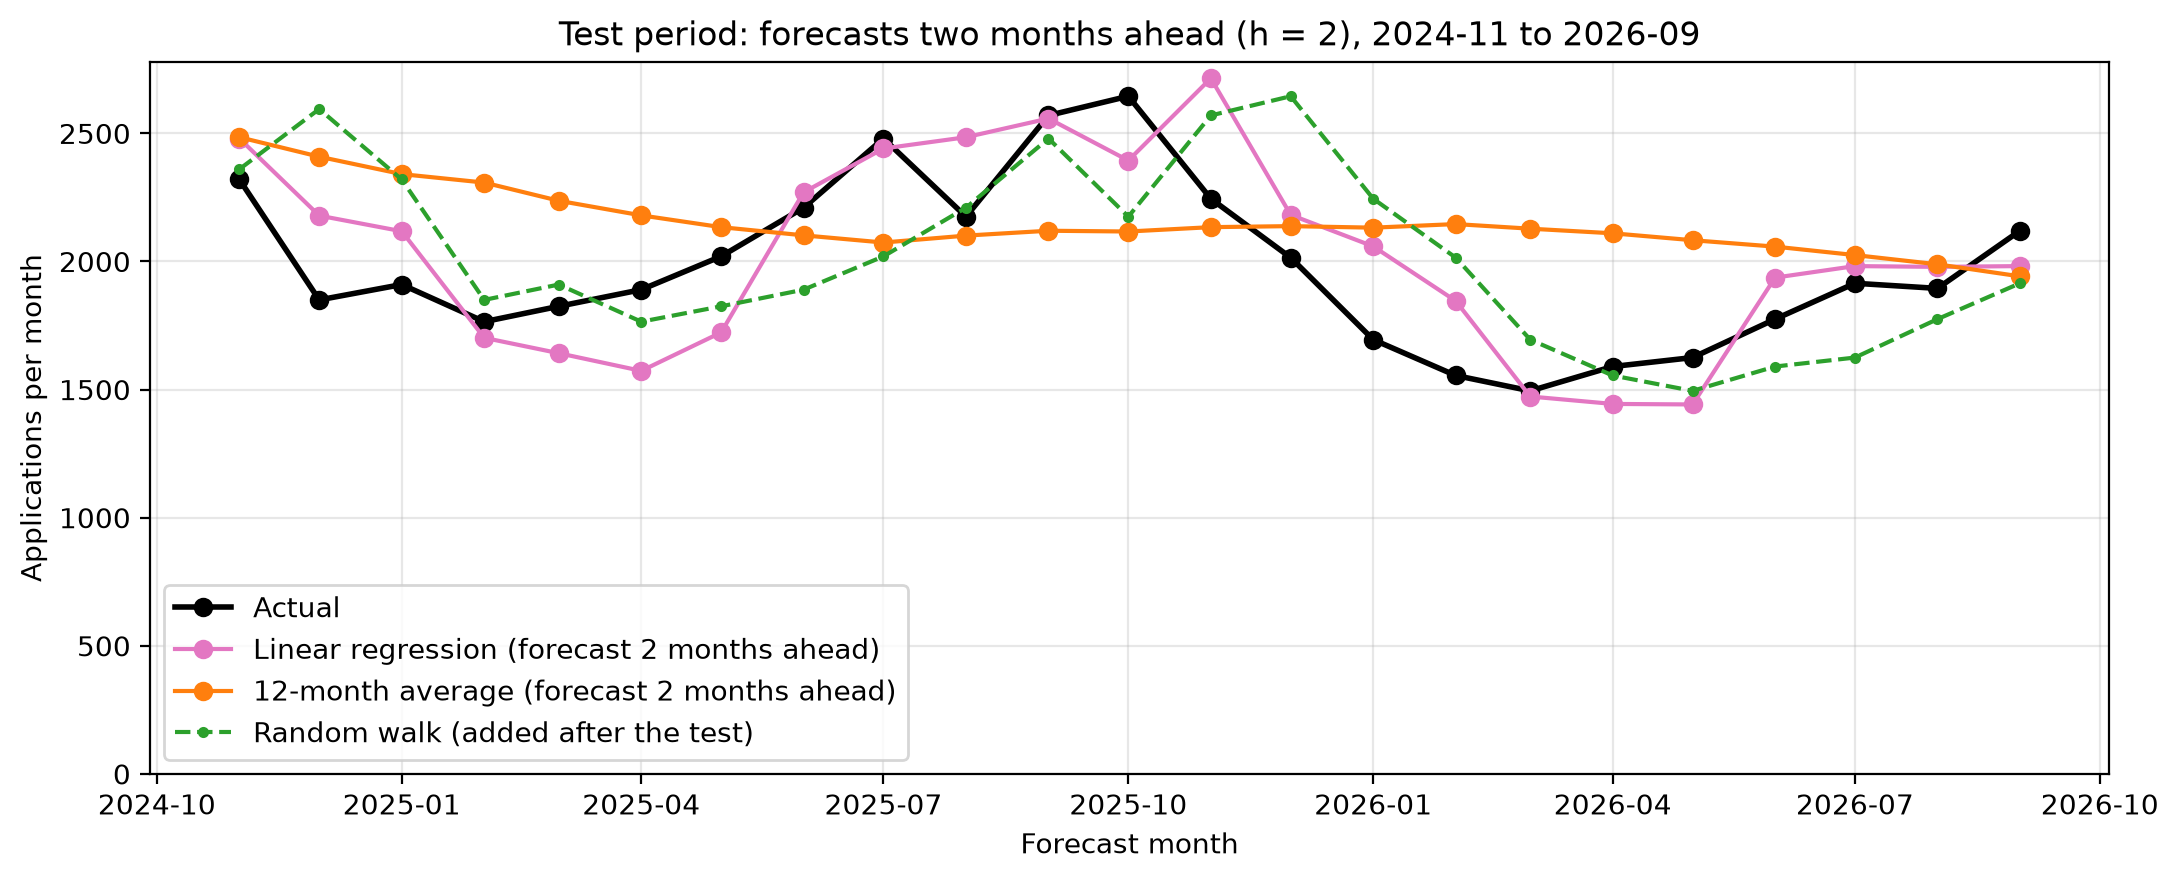

In [9]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(monthly.index, monthly["Actual"], color="black", linewidth=2, marker="o", label="Actual")
ax.plot(monthly.index, monthly["Linear regression"], color=plt.cm.tab10(6), marker="o", label="Linear regression (forecast 2 months ahead)")
ax.plot(monthly.index, monthly["12-month average"], color=plt.cm.tab10(1), marker="o", label="12-month average (forecast 2 months ahead)")
ax.plot(monthly.index, monthly["Random walk"], color=plt.cm.tab10(2), linestyle="--", marker=".", label="Random walk (added after the test)")
ax.set_title("Test period: forecasts two months ahead (h = 2), 2024-11 to 2026-09")
ax.set_xlabel("Forecast month")
ax.set_ylabel("Applications per month")
ax.set_ylim(bottom=0)
ax.legend(loc="lower left")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../output/figures/04_test_forecasts_h2.png")
plt.show()

In the plot, the 12-month average is almost a flat line between about 2,000 and 2,500. It cannot follow the rise in summer and autumn 2025 or the fall in early 2026, because it averages a whole year. The linear regression follows the seasonal pattern, the rise from June to October 2025 and again from June 2026, and in 14 of the 23 months it misses by 200 or less (table above).

Its largest errors come right after turning points. It was too low in March to May 2025 (−183 to −317), and too high from November 2025 to February 2026 (+470 in November, +364 in January), when the numbers had already turned down. In November 2025, for example, September had just jumped from 2,175 to 2,570, and the model forecast 2,715; the actual number was 2,245. The random walk (dashed line) is simply the actual curve shifted by two months, since it repeats the number of two months earlier. So it is late at every turn: for December 2025 it said 2,645 when the actual number was 2,015.

So the model reacts to the newest changes, but only once they are visible in the data, so it cannot see a turning point coming. A planner can use it as a monthly guide, but should expect misses of a few hundred applications around turning points.

## 7. Save the test forecasts

We save all test forecasts, because `05_ranges_and_forecast.ipynb` uses them to check how often the actual numbers fall inside our forecast ranges.

In [10]:
test_forecasts.drop(columns=["abs_error", "sq_error_log"]).to_csv("../data/processed/test_forecasts.csv", index=False)
print("Saved", test_forecasts.shape[0], "test forecasts")

Saved 207 test forecasts


## Summary

In this notebook, the order mattered. The linear regression on the series' own past was chosen in `03_evaluate.ipynb`, section 8, and saved on GitHub before this notebook was run, and we did not change it after seeing the results.

The model passes the test. Two months ahead, it misses by 188 applications per month, against 331 for the 12-month average: **43% lower MAE** and 41% lower RMSE in logs. Our 10% rule against the 12-month average is met, and the ranking holds at $h = 1$ and $h = 3$. For information, the random walk, added after the test run, misses by 269: our model is 30% lower.

But the result must be read with care. The test period, October 2024 to September 2026, was calm, so all three have smaller errors than in the backtest, and it holds only 23 forecasts at $h = 2$. The largest misses come after turning points, which the model cannot see coming.

Finally, we did not change our choice after seeing the test. We ran this notebook again after adding the random walk, and the forecasts and errors of the chosen model stayed the same. The best SARIMA model was not tested, so this test says nothing about our model against SARIMA.